# Predicción del consumo de energía · Usuarios especiales de Electrohuila

| | |
|---|---|
| **Versión** | 3.0 · 2026-11-08 |
| **Objetivo** | Pronosticar el consumo mensual de energía activa (kWh) hasta **diciembre de 2027** en tres niveles: total (global), por usuario y por cuenta, y elegir con evidencia el modelo que mejor predice. |
| **Entrada** | `data/input/consumos.xlsx` (misma fuente y consolidación de 152 usuarios del análisis exploratorio) y `data/input/variables_externas.csv` (calendario: días hábiles y festivos de Colombia). |
| **Salidas** | `data/output/predicciones.xlsx`, `data/output/indicadores.xlsx`, `data/output/modelos/modelo_global.joblib`, figuras en `data/output/reportes/prediccion/figuras/` y los datos del dashboard en `static/js/data.js`. |
| **Código** | La lógica está en `src/` (`procesamiento.py`, `prediccion.py`, `utils.py`); este cuaderno la ejecuta paso a paso, muestra los resultados y los interpreta. |

**Cambios frente a la versión anterior (`predición.ipynb`).** Se mantienen los tres niveles, el horizonte a diciembre de 2027, la búsqueda de hiperparámetros con `GridSearchCV` + `TimeSeriesSplit` y el modelo persistido. Se corrige y amplía:

1. **Mes incompleto.** Octubre de 2026 solo tiene 2 registros; antes entraba a la serie como una caída falsa. Ahora se excluye (último mes completo: septiembre de 2026).
2. **Validación más robusta.** Antes se evaluaba una sola ventana de prueba. Ahora se usa **validación con origen móvil**: 5 orígenes y 12 meses hacia adelante en cada uno, sin usar información futura.
3. **Más modelos y métricas.** Se agregan Holt-Winters y la regresión estacional. Además de MAE, RMSE y MAPE se reportan **R²**, WAPE, sesgo, MASE y la mejora frente al naive estacional.
4. **Variables externas.** Se incluyen los días hábiles de cada mes (festivos de Colombia).
5. **Incertidumbre.** El pronóstico global trae intervalos del 80 % y del 95 %.
6. **Selección por entidad.** Cada usuario y cada cuenta usa el modelo que mejor predijo su propia serie.
7. **Privacidad e identificación.** Los nombres de personas naturales se reemplazan por su código; las cuentas se muestran con su número real para poder ubicarlas.

**Cómo usar.** Abra el cuaderno desde la carpeta `homework/` o desde la raíz del proyecto y ejecute *Restart* → *Run All* (tarda unos 4 minutos). El mismo flujo se ejecuta sin el cuaderno con `python -m src.prediccion`.

In [1]:
# =============================================================================
# 0. CONFIGURACIÓN
# =============================================================================
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == 'homework' else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import warnings
import sklearn

from src import utils, procesamiento as pr, prediccion as P

VERSION = '3.0'
utils.aplicar_estilo()
FIG = utils.Figuras()                      # numera y guarda en data/output/reportes/prediccion/figuras
COL = utils.COLORES_MODELO
GWH = 1e6
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
warnings.filterwarnings('ignore', category=matplotlib.MatplotlibDeprecationWarning)


def eje_gwh(ax, dec=0):
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, p: utils.fmt_es(v, dec)))


print(f'Cuaderno v{VERSION} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}')

Cuaderno v3.0 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. Datos para el modelado

Se reutiliza la consolidación del análisis exploratorio (`src/procesamiento.py`). Cada cuenta toma el nombre de su titular actual y las variantes de escritura se unen con el mismo diccionario `REMPLAZAR`, lo que da 152 usuarios. Se modela la **serie mensual total en kWh** desde enero de 2020 hasta el último mes completo.

Además, se generan dos insumos en `data/input/`:
- `usuarios.xlsx`: catálogo de usuarios y cuentas, con sus códigos;
- `variables_externas.csv`: días del mes, días hábiles, sábados, domingos y festivos entre semana, de 2020 a 2027.

Los festivos se calculan con la Ley 51 de 1983: fechas fijas, festivos trasladados al lunes y los que dependen de la Pascua. El archivo admite columnas nuevas, como temperatura o actividad económica, siempre que cubran también los meses a pronosticar.

In [2]:
base = pr.preparar_base()
pr.escribir_catalogo_usuarios(base)
pr.escribir_variables_externas('2020-01-01', f'{P.MES_OBJETIVO}-01')
serie, cal = P.datos_modelado(base)

print(f'Serie global: {serie.index[0]:%Y-%m} a {serie.index[-1]:%Y-%m} · {len(serie)} meses · {serie.sum() / GWH:,.1f} GWh')
print(f'Meses excluidos por incompletos: {", ".join(base.excluidos["FECHA"].dt.strftime("%Y-%m").unique())} '
      f'({len(base.excluidos)} registros)')
print(f'Usuarios consolidados: {len(base.usuarios)} · con datos en el periodo: {base.analisis["USUARIO"].nunique()} · '
      f'cuentas: {base.analisis["CUENTA"].nunique()}')
print(f'Horizonte de pronóstico: {serie.index[-1] + pd.offsets.MonthBegin(1):%Y-%m} a {P.MES_OBJETIVO}')
cal.loc['2026-07':'2027-12'].T

Serie global: 2020-01 a 2026-09 · 81 meses · 978.2 GWh
Meses excluidos por incompletos: 2026-10 (2 registros)
Usuarios consolidados: 152 · con datos en el periodo: 151 · cuentas: 700
Horizonte de pronóstico: 2026-10 a 2027-12


FECHA,2026-07-01,2026-08-01,2026-09-01,2026-10-01,2026-11-01,2026-12-01,2027-01-01,2027-02-01,2027-03-01,2027-04-01,2027-05-01,2027-06-01,2027-07-01,2027-08-01,2027-09-01,2027-10-01,2027-11-01,2027-12-01
DIAS_MES,31,31,30,31,30,31,31,28,31,30,31,30,31,31,30,31,30,31
DIAS_HABILES,22,19,22,21,19,21,19,20,20,22,19,21,20,21,22,20,20,22
SABADOS,4,5,4,5,4,4,5,4,4,4,5,4,5,4,4,5,4,4
DOMINGOS,4,5,4,4,5,4,5,4,4,4,5,4,4,5,4,5,4,4
FESTIVOS_ENTRE_SEMANA,1,2,0,1,2,2,2,0,3,0,2,1,2,1,0,1,2,1


**Interpretación — datos.**
- **Qué muestra:** la serie que se va a pronosticar y las variables de calendario de los meses futuros.
- **Hallazgos:** hay 81 meses completos (enero de 2020 a septiembre de 2026) con 978,2 GWh, igual al total del análisis exploratorio. Los días hábiles varían entre 18 y 23 por mes.

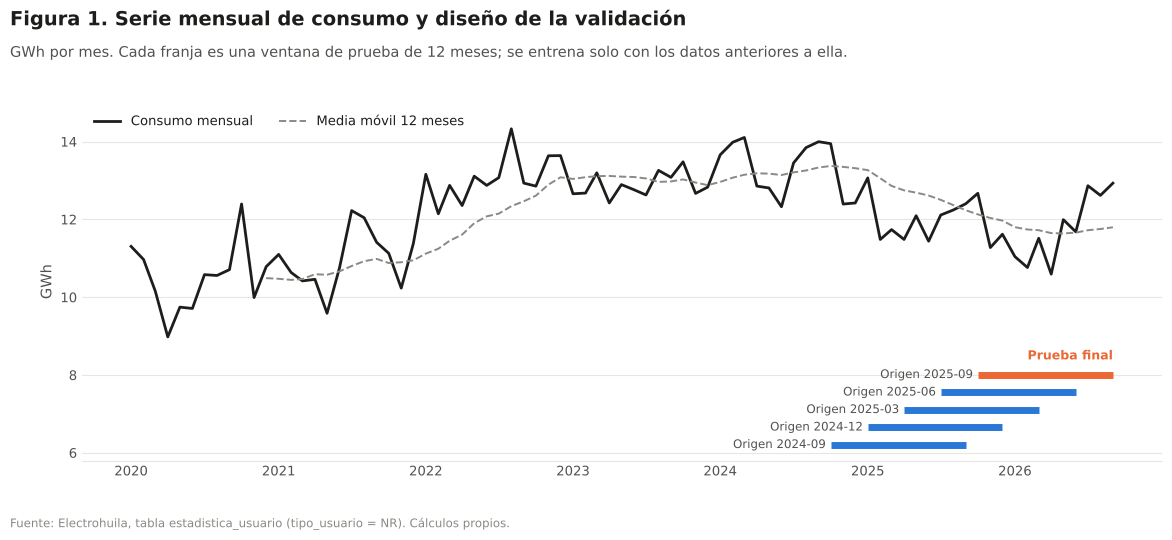

In [3]:
origenes = P.origenes_validacion(len(serie))
fig, ax = FIG.nueva('Serie mensual de consumo y diseño de la validación',
                    'GWh por mes. Cada franja es una ventana de prueba de 12 meses; se entrena solo con los datos anteriores a ella.',
                    alto=5.2)
ax.plot(serie.index, serie / GWH, color=utils.TINTA, lw=2, label='Consumo mensual')
ax.plot(serie.index, serie.rolling(12).mean() / GWH, color=utils.TINTA_3, lw=1.4, ls='--', label='Media móvil 12 meses')
for k, n_tr in enumerate(origenes):
    ini, fin = serie.index[n_tr], serie.index[min(n_tr + 11, len(serie) - 1)]
    y0 = 6.2 + k * 0.45
    ax.plot([ini, fin], [y0, y0], color=utils.AZUL if k < len(origenes) - 1 else utils.NARANJA, lw=5, solid_capstyle='butt')
    ax.text(ini - pd.Timedelta(days=12), y0, f'Origen {serie.index[n_tr - 1]:%Y-%m}', ha='right', va='center', fontsize=8.5,
            color=utils.TINTA_2)
ax.set_ylim(5.8, 15); ax.set_ylabel('GWh')
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(loc='upper left', ncol=2)
ax.text(serie.index[-1], 6.2 + 4 * 0.45 + 0.4, 'Prueba final', color=utils.NARANJA, ha='right', fontsize=9, fontweight='bold')
FIG.guardar(fig, 'serie_y_validacion')

Correlación índice de consumo vs días hábiles: r = 0.37 · pendiente 1.76 puntos por día hábil


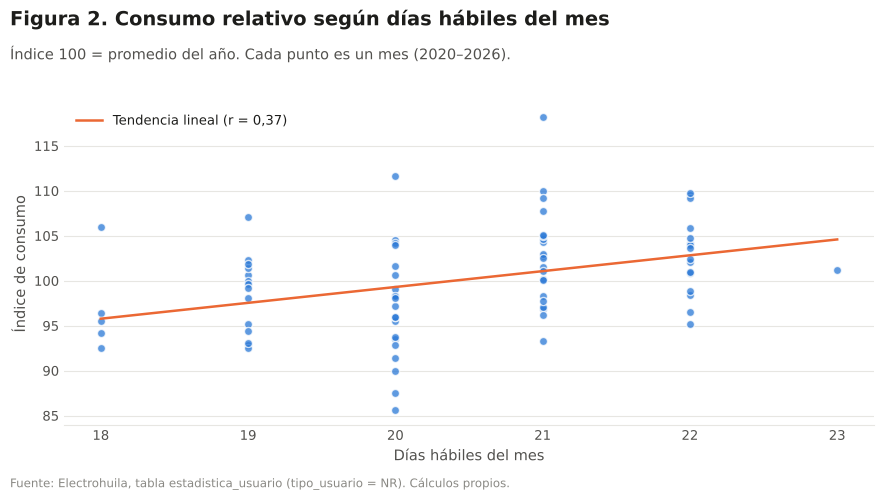

In [4]:
# Relación entre los días hábiles y el consumo, sin el efecto del nivel de cada año
rel = pd.DataFrame({'y': serie, 'hab': cal.reindex(serie.index)['DIAS_HABILES']})
rel['indice'] = rel['y'] / rel.groupby(rel.index.year)['y'].transform('mean') * 100
r = rel[['indice', 'hab']].corr().iloc[0, 1]
fig, ax = FIG.nueva('Consumo relativo según días hábiles del mes',
                    'Índice 100 = promedio del año. Cada punto es un mes (2020–2026).', ancho=9, alto=4.8)
ax.scatter(rel['hab'], rel['indice'], s=34, color=utils.AZUL, alpha=.75, edgecolor='white')
b = np.polyfit(rel['hab'], rel['indice'], 1)
xs = np.linspace(rel['hab'].min(), rel['hab'].max(), 10)
ax.plot(xs, np.polyval(b, xs), color=utils.NARANJA, lw=1.8, label=f'Tendencia lineal (r = {utils.fmt_es(r, 2)})')
ax.set_xlabel('Días hábiles del mes'); ax.set_ylabel('Índice de consumo'); ax.legend(loc='upper left')
FIG.guardar(fig, 'consumo_vs_dias_habiles')
print(f'Correlación índice de consumo vs días hábiles: r = {r:.2f} · pendiente {b[0]:.2f} puntos por día hábil')

**Interpretación — calendario.**
- **Qué muestra:** el consumo de cada mes frente al promedio de su año, según cuántos días hábiles tuvo el mes.
- **Hallazgos:** hay una relación positiva moderada (r ≈ 0,37). Cada día hábil adicional sube el consumo del mes cerca de 1,8 puntos frente al promedio del año, pero la dispersión es grande. Una parte importante del consumo es continua (alumbrado público, hospitales, piscícolas, bombeo) y no depende de que el día sea laboral.

## 2. Modelos candidatos

Se comparan siete modelos, de los más simples a los de aprendizaje automático. Los dos primeros son referencias: un modelo útil debe superarlas. Los modelos de aprendizaje automático usan los consumos de 1, 2, 3 y 12 meses antes, la estacionalidad (seno y coseno del mes), una tendencia y los días hábiles. Pronostican de forma **recursiva**: cada mes pronosticado se usa como dato para el siguiente.

In [5]:
pd.DataFrame({'Modelo': list(P.CATALOGO), 'Descripción': list(P.CATALOGO.values()),
              'Meses mínimos de entrenamiento': [P.crear_modelo(m, cal).min_obs for m in P.CATALOGO]}).set_index('Modelo')

,Descripción,Meses mínimos de entrenamiento
Modelo,,
Naive estacional,Repite el valor del mismo mes del año anterior...,12
Promedio móvil 12 m,Proyecta plano el promedio de los últimos 12 m...,1
Holt-Winters,"Suavizamiento exponencial con nivel, tendencia...",24
Regresión estacional,"Ridge con tendencia lineal, un indicador por m...",24
Ridge con rezagos,"Ridge sobre los consumos de 1, 2, 3 y 12 meses...",36
Random Forest,Bosque aleatorio con las mismas variables de r...,36
Gradient Boosting,Gradient boosting por histogramas con las mism...,36


## 3. Validación temporal con origen móvil

En series de tiempo no se puede mezclar el orden de los datos, como haría una validación cruzada aleatoria, porque el modelo vería el futuro. Por eso se aplica **validación con origen móvil** (Tashman, 2000; Hyndman y Athanasopoulos, 2021):

1. **Entrenamiento:** se entrena con los datos hasta un mes de corte (origen).
2. **Pronóstico:** se pronostican los 12 meses siguientes y se comparan con lo real.
3. **Repetición:** se repite con 5 orígenes separados 3 meses (sep-2024, dic-2024, mar-2025, jun-2025 y sep-2025). El último es la **prueba final**: entrena hasta septiembre de 2025 y pronostica octubre de 2025 a septiembre de 2026.
4. **Hiperparámetros:** dentro de cada entrenamiento, `GridSearchCV` con `TimeSeriesSplit(3)` elige los hiperparámetros de Ridge, Random Forest y Gradient Boosting usando solo esos datos de entrenamiento.

**Criterio de selección.** Gana el modelo con menor **MAPE promedio en la validación**, es decir, en los 60 pronósticos (5 orígenes × 12 meses). Las demás métricas se usan para confirmar la elección.

In [6]:
bt, hiper = P.validar(serie, cal)
comp = P.comparar(bt)
MEJOR = comp['mejor']
ORDEN = list(comp['cv'].index)
print(f'\nPronósticos evaluados: {len(bt):,} · mejor modelo según {comp["criterio"]}: {MEJOR}')
hiper[hiper['Origen'] == comp['origen_prueba']].set_index('Modelo')[['Parámetros', 'Segundos']]

  origen 2024-09: 7 modelos evaluados
  origen 2024-12: 7 modelos evaluados
  origen 2025-03: 7 modelos evaluados
  origen 2025-06: 7 modelos evaluados
  origen 2025-09: 7 modelos evaluados

Pronósticos evaluados: 420 · mejor modelo según MAPE_%: Gradient Boosting


,Parámetros,Segundos
Modelo,,
Naive estacional,{},0.00
Promedio móvil 12 m,{},0.00
Holt-Winters,"{'alpha': 0.451, 'beta': 0.0, 'gamma': 0.636, ...",0.03
Regresión estacional,{'alpha': 100.0},0.03
Ridge con rezagos,{'alpha': 10},0.04
Random Forest,"{'max_depth': 3, 'min_samples_leaf': 1}",7.87
Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 5, '...",1.46


## 4. Comparación de modelos

| Métrica | Qué mide | Mejor |
|---|---|---|
| **MAE** | Error absoluto medio (GWh) | menor |
| **RMSE** | Raíz del error cuadrático medio; penaliza más los errores grandes (GWh) | menor |
| **MAPE** | Error absoluto medio en % del valor real | menor |
| **WAPE** | Σ\|error\| / Σ real: error % ponderado por volumen | menor |
| **R²** | Proporción de la variación mes a mes que explica el pronóstico. Puede ser negativo si el modelo predice peor que la media del periodo | mayor (máx. 1) |
| **Sesgo** | Σ(pronóstico − real) / Σ real; positivo = sobrestima | cercano a 0 |
| **MASE** | MAE dividido por el MAE del naive estacional dentro del entrenamiento (Hyndman y Koehler, 2006); < 1 = mejor que el naive | menor |
| **Mejora vs naive** | % de reducción del MAE frente al naive estacional | mayor |

In [7]:
def tabla_metricas(t):
    t = t.copy()
    t[['MAE', 'RMSE']] = t[['MAE', 'RMSE']] / GWH
    return t.rename(columns={'MAE': 'MAE (GWh)', 'RMSE': 'RMSE (GWh)', 'MAPE_%': 'MAPE %', 'WAPE_%': 'WAPE %', 'R2': 'R²',
                             'Sesgo_%': 'Sesgo %', 'Mejora_vs_naive_%': 'Mejora vs naive %'}).round(3)

print('VALIDACIÓN CRUZADA TEMPORAL (5 orígenes × 12 meses)')
display(tabla_metricas(comp['cv']))
print(f'PRUEBA FINAL (entrenado hasta {comp["origen_prueba"]:%Y-%m}, evaluado en los 12 meses siguientes)')
tabla_metricas(comp['prueba'])

VALIDACIÓN CRUZADA TEMPORAL (5 orígenes × 12 meses)
PRUEBA FINAL (entrenado hasta 2025-09, evaluado en los 12 meses siguientes)


,MAE (GWh),RMSE (GWh),MAPE %,WAPE %,R²,Sesgo %,MASE,Mejora vs naive %,Ranking
Modelo,,,,,,,,,
Gradient Boosting,0.85,1.00,7.23,7.14,-1.17,5.77,0.81,21.71,1
Random Forest,0.85,0.98,7.30,7.17,-1.11,5.34,0.81,21.30,2
Holt-Winters,0.95,1.17,8.14,8.02,-1.96,5.75,0.91,12.01,3
Ridge con rezagos,1.04,1.18,9.02,8.80,-2.02,8.47,1.00,3.48,4
Naive estacional,1.08,1.24,9.18,9.12,-2.37,8.38,1.03,0.00,5
Promedio móvil 12 m,1.09,1.23,9.41,9.18,-2.27,8.38,1.04,-0.63,6
Regresión estacional,1.81,1.95,15.53,15.28,-7.28,15.28,1.73,-67.56,7


,MAE (GWh),RMSE (GWh),MAPE %,WAPE %,R²,Sesgo %,MASE,Mejora vs naive %,Ranking
Modelo,,,,,,,,,
Gradient Boosting,0.61,0.67,5.24,5.14,0.27,1.43,0.56,19.66,1
Holt-Winters,0.64,0.84,5.65,5.42,-0.14,3.19,0.59,15.23,2
Ridge con rezagos,0.70,0.88,6.21,5.90,-0.24,4.95,0.65,7.86,3
Naive estacional,0.76,0.92,6.51,6.40,-0.36,3.71,0.70,0.00,4
Random Forest,0.78,0.88,6.77,6.65,-0.26,2.12,0.73,-3.85,5
Promedio móvil 12 m,0.80,0.90,6.96,6.74,-0.31,3.71,0.74,-5.36,6
Regresión estacional,0.97,1.15,8.58,8.19,-1.16,8.19,0.90,-27.97,7


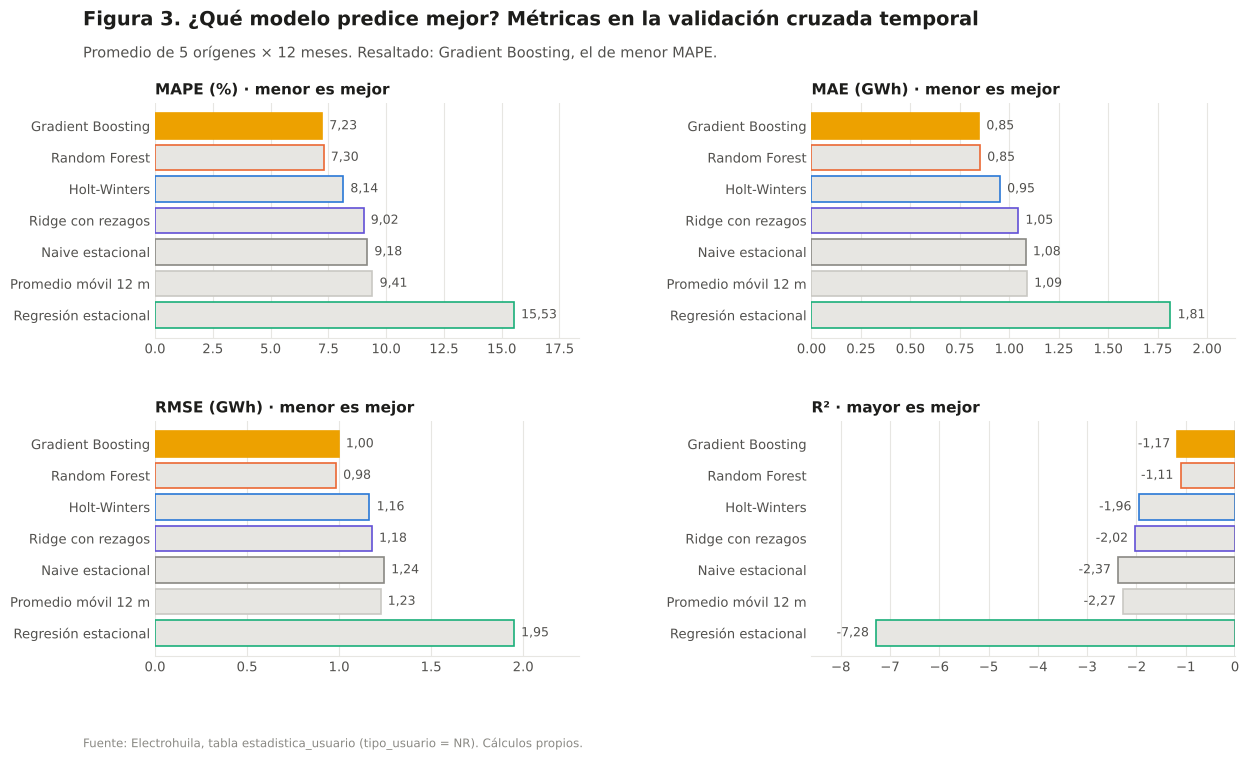

In [8]:
cv = comp['cv']
paneles = [('MAPE_%', 'MAPE (%)', 1, 'menor es mejor'), ('MAE', 'MAE (GWh)', GWH, 'menor es mejor'),
           ('RMSE', 'RMSE (GWh)', GWH, 'menor es mejor'), ('R2', 'R²', 1, 'mayor es mejor')]
fig, axes = FIG.nueva('¿Qué modelo predice mejor? Métricas en la validación cruzada temporal',
                      f'Promedio de 5 orígenes × 12 meses. Resaltado: {MEJOR}, el de menor MAPE.',
                      alto=7.4, filas=2, columnas=2)
for ax, (col, tit, div, nota) in zip(axes.flat, paneles):
    v = cv[col] / div
    colores = [COL[m] if m == MEJOR else utils.REJILLA for m in cv.index]
    bars = ax.barh(cv.index[::-1], v[::-1], color=colores[::-1], edgecolor=[COL[m] for m in cv.index[::-1]], lw=1.2)
    ax.set_title(f'{tit} · {nota}', fontsize=11)
    ax.grid(axis='x'); ax.grid(axis='y', visible=False)
    for b_, val in zip(bars, v[::-1]):
        ax.text(b_.get_width() + (abs(v).max() * 0.02) * (1 if val >= 0 else -1), b_.get_y() + b_.get_height() / 2,
                utils.fmt_es(val, 2), va='center', ha='left' if val >= 0 else 'right', fontsize=9, color=utils.TINTA_2)
    if col == 'R2':
        ax.axvline(0, color=utils.TINTA_3, lw=1)
    ax.margins(x=0.18)
fig.subplots_adjust(hspace=0.35, wspace=0.55)
FIG.guardar(fig, 'comparacion_metricas_modelos')

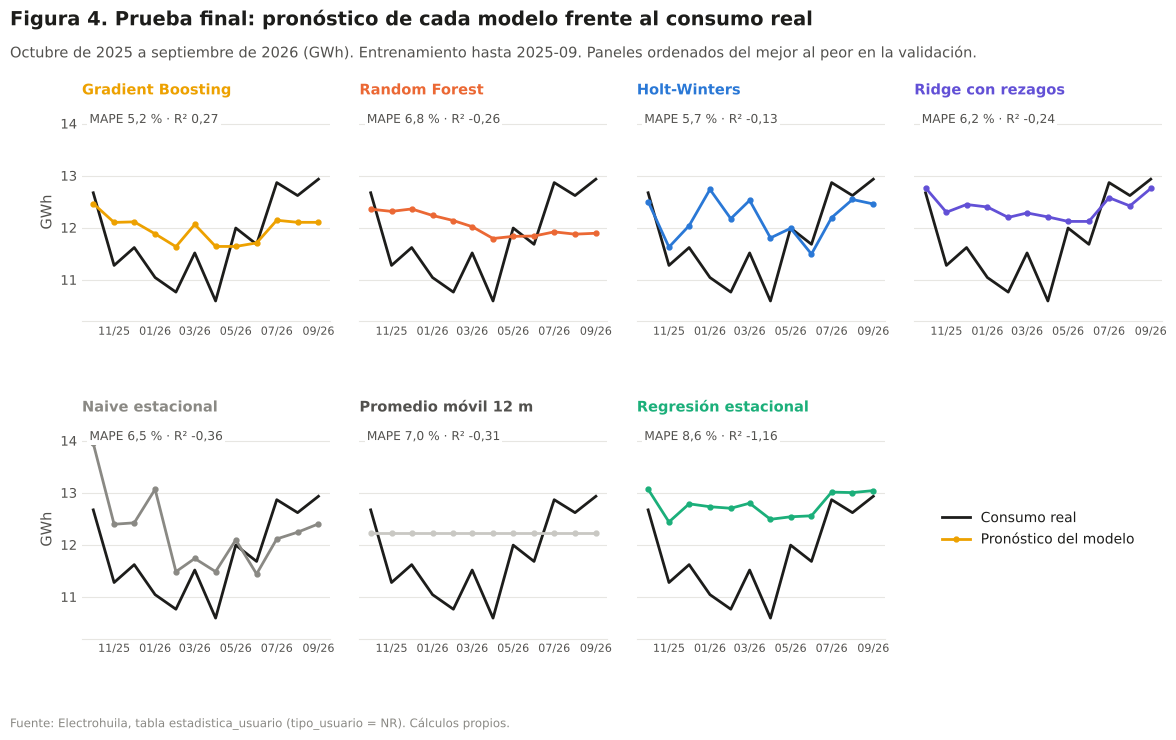

In [9]:
prueba = bt[bt['Origen'] == comp['origen_prueba']]
fig, axes = FIG.nueva('Prueba final: pronóstico de cada modelo frente al consumo real',
                      f'Octubre de 2025 a septiembre de 2026 (GWh). Entrenamiento hasta {comp["origen_prueba"]:%Y-%m}. '
                      'Paneles ordenados del mejor al peor en la validación.', alto=7.2, filas=2, columnas=4, sharey=True)
real = serie.loc[prueba['FECHA'].min():]
for ax, m in zip(axes.flat, ORDEN):
    d = prueba[prueba['Modelo'] == m].sort_values('FECHA')
    ax.plot(real.index, real / GWH, color=utils.TINTA, lw=2, label='Real')
    ax.plot(d['FECHA'], d['Pronóstico'] / GWH, color=COL[m], lw=2, marker='o', ms=3.5, label='Pronóstico')
    mt = comp['prueba'].loc[m]
    ax.set_title(m, fontsize=10.5, color=COL[m] if m != 'Promedio móvil 12 m' else utils.TINTA_2)
    ax.text(0.03, 0.95, f"MAPE {utils.fmt_es(mt['MAPE_%'], 1)} % · R² {utils.fmt_es(mt['R2'], 2)}", transform=ax.transAxes,
            fontsize=8.8, color=utils.TINTA_2, va='top', bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5})
    ax.set_ylim(10.2, 14.4)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y')); ax.tick_params(axis='x', labelsize=8)
axes.flat[-1].axis('off')
h_, l_ = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(h_, ['Consumo real', 'Pronóstico del modelo'], loc='center', fontsize=10)
axes.flat[0].set_ylabel('GWh'); axes.flat[4].set_ylabel('GWh')
fig.subplots_adjust(hspace=0.45, wspace=0.12)
FIG.guardar(fig, 'prueba_final_por_modelo')

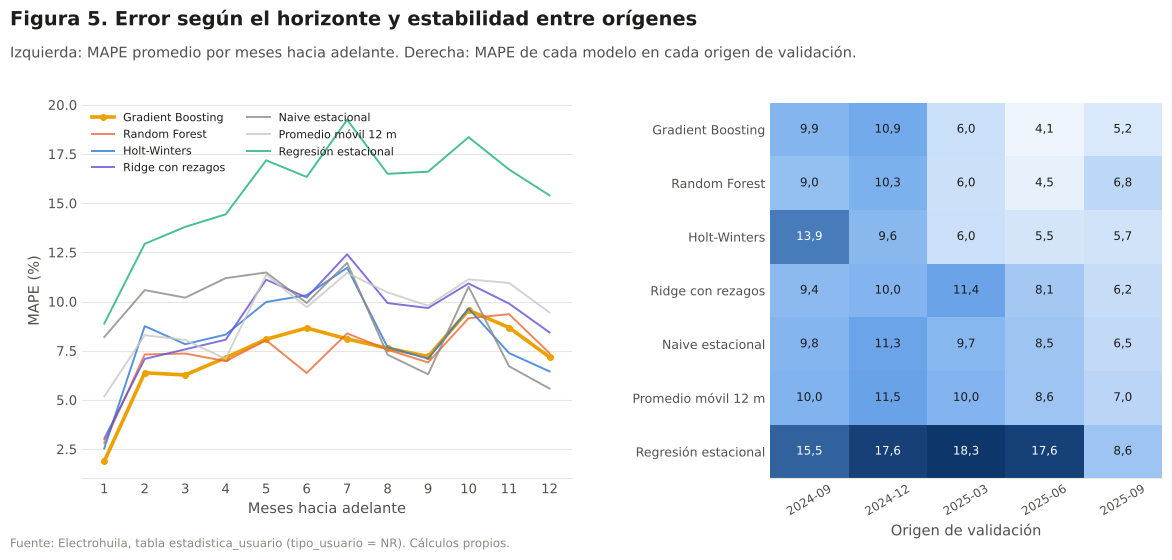

In [10]:
fig, (a1, a2) = FIG.nueva('Error según el horizonte y estabilidad entre orígenes',
                          'Izquierda: MAPE promedio por meses hacia adelante. Derecha: MAPE de cada modelo en cada origen de validación.',
                          alto=5.4, columnas=2, gridspec_kw={'width_ratios': [1.25, 1]})
for m in ORDEN:
    a1.plot(comp['por_h'].index, comp['por_h'][m], color=COL[m], lw=2.6 if m == MEJOR else 1.4,
            alpha=1 if m == MEJOR else .8, marker='o' if m == MEJOR else None, ms=4, label=m)
a1.set_xlabel('Meses hacia adelante'); a1.set_ylabel('MAPE (%)'); a1.set_xticks(range(1, 13))
a1.legend(fontsize=8, ncol=2, loc='upper left')
po = comp['por_origen']
im = a2.imshow(po.values, cmap=matplotlib.colors.LinearSegmentedColormap.from_list('e', ['#eef5fd', '#6da7ec', '#0d366b']), aspect='auto')
a2.set_yticks(range(len(po))); a2.set_yticklabels(po.index, fontsize=9)
a2.set_xticks(range(po.shape[1])); a2.set_xticklabels([f'{o:%Y-%m}' for o in po.columns], fontsize=8.5, rotation=30)
for i in range(po.shape[0]):
    for j in range(po.shape[1]):
        v = po.values[i, j]
        a2.text(j, i, utils.fmt_es(v, 1), ha='center', va='center', fontsize=8.5, color='white' if v > po.values.mean() * 1.3 else utils.TINTA)
a2.grid(False); a2.set_xlabel('Origen de validación')
fig.subplots_adjust(wspace=0.45)
FIG.guardar(fig, 'error_horizonte_y_origen')

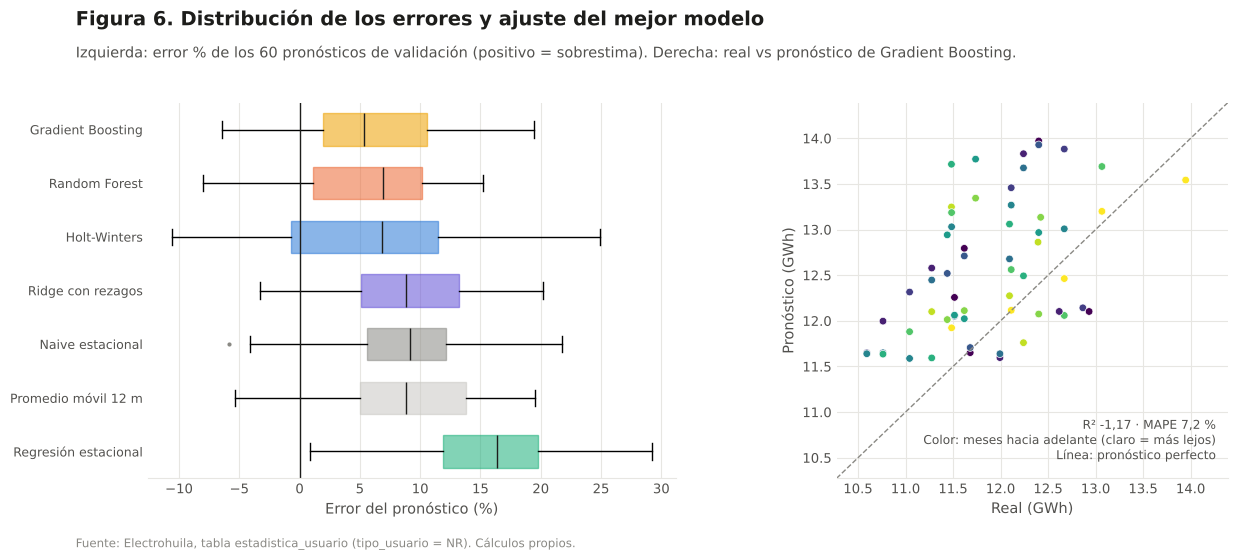

In [11]:
fig, (a1, a2) = FIG.nueva('Distribución de los errores y ajuste del mejor modelo',
                          f'Izquierda: error % de los 60 pronósticos de validación (positivo = sobrestima). Derecha: real vs pronóstico de {MEJOR}.',
                          alto=5.4, columnas=2, gridspec_kw={'width_ratios': [1.35, 1]})
datos_err = [bt.loc[bt['Modelo'] == m, 'Error_%'].values for m in ORDEN]
bp = a1.boxplot(datos_err, vert=False, patch_artist=True, widths=0.6, medianprops={'color': utils.TINTA},
                flierprops={'marker': 'o', 'ms': 3, 'markerfacecolor': utils.TINTA_3, 'markeredgecolor': 'none'})
for patch, m in zip(bp['boxes'], ORDEN):
    patch.set_facecolor(COL[m]); patch.set_alpha(.55); patch.set_edgecolor(COL[m])
a1.set_yticks(range(1, len(ORDEN) + 1)); a1.set_yticklabels(ORDEN, fontsize=9); a1.invert_yaxis()
a1.axvline(0, color=utils.TINTA, lw=1); a1.set_xlabel('Error del pronóstico (%)'); a1.grid(axis='x'); a1.grid(axis='y', visible=False)
d = bt[bt['Modelo'] == MEJOR]
a2.scatter(d['Real'] / GWH, d['Pronóstico'] / GWH, c=d['H'], cmap='viridis_r', s=30, edgecolor='white', lw=.5)
lim = [min(d['Real'].min(), d['Pronóstico'].min()) / GWH * .97, max(d['Real'].max(), d['Pronóstico'].max()) / GWH * 1.03]
a2.plot(lim, lim, color=utils.TINTA_3, ls='--', lw=1); a2.set_xlim(lim); a2.set_ylim(lim)
a2.set_xlabel('Real (GWh)'); a2.set_ylabel('Pronóstico (GWh)'); a2.grid(axis='x')
mv = comp['cv'].loc[MEJOR]
a2.text(0.97, 0.04, f"R² {utils.fmt_es(mv['R2'], 2)} · MAPE {utils.fmt_es(mv['MAPE_%'], 1)} %\nColor: meses hacia adelante (claro = más lejos)\nLínea: pronóstico perfecto",
        transform=a2.transAxes, fontsize=8.8, va='bottom', ha='right', color=utils.TINTA_2)
fig.subplots_adjust(wspace=0.35)
FIG.guardar(fig, 'errores_y_ajuste_mejor_modelo')

**Interpretación — comparación de modelos.**
- **Qué muestra:** las métricas de los siete modelos en la validación (60 pronósticos) y en la prueba final, el error según los meses hacia adelante, la estabilidad entre orígenes y la distribución de los errores.
- **Hallazgos:**
  - **Gradient Boosting gana en las dos evaluaciones.** En la validación tiene MAPE ≈ 7,2 % y MAE ≈ 0,85 GWh/mes, y en la prueba final MAPE ≈ 5,2 % y R² ≈ 0,27.
  - **Random Forest queda muy cerca en la validación** (MAPE ≈ 7,3 %), y Holt-Winters es el tercero (≈ 8,1 %). Los tres reducen el MAE frente al naive estacional (MASE < 1).
  - **En la prueba final Random Forest cae al 5.º lugar** (MAPE ≈ 6,8 %, peor que el naive), mientras que Gradient Boosting sigue primero. Gradient Boosting es el más consistente de los dos.
  - **Los demás aportan poco o nada.** Ridge con rezagos apenas mejora al naive (≈ 3,5 % menos MAE en la validación). La regresión estacional es la peor (MAPE ≈ 15,5 %): extrapola la tendencia de crecimiento de 2020–2022 y falla cuando el consumo cae en 2025.
  - **R² negativo en la validación (todos los modelos).** No es un error de cálculo: dentro de cada ventana de 12 meses el consumo varía poco (±0,7 GWh) frente al cambio de nivel de 2025, que ningún modelo anticipó. En la prueba final, con un nivel estable, solo Gradient Boosting logra R² positivo.
  - **Sesgo positivo (+5 a +15 %).** Todos sobrestimaron en los orígenes de 2024 y 2025 por la caída de consumo de 2025 descrita en el análisis exploratorio.

## 5. Pronóstico global hasta diciembre de 2027

El modelo ganador se reentrena con los 81 meses (incluida la búsqueda de hiperparámetros) y pronostica de octubre de 2026 a diciembre de 2027.

Los **intervalos** son empíricos: se toma el percentil 80, 90 y 95 del error relativo absoluto que tuvo el modelo en la validación, según el horizonte (1–3, 4–6 y 7–12 meses). Para horizontes mayores a 12 meses se amplían en proporción a √(h/12).

In [12]:
pron, modelo_final = P.pronostico_final(serie, cal, MEJOR, bt)
print('Hiperparámetros del modelo final:', modelo_final.params)
t = pron.set_index('FECHA')[['Pronóstico_kWh', 'Inferior_80', 'Superior_80', 'Inferior_90', 'Superior_90', 'Inferior_95', 'Superior_95']] / GWH
t.index = t.index.strftime('%Y-%m')
t.columns = ['Pronóstico (GWh)', 'Inferior 80 %', 'Superior 80 %', 'Inferior 90 %', 'Superior 90 %', 'Inferior 95 %', 'Superior 95 %']
t.round(2)

Hiperparámetros del modelo final: {'learning_rate': 0.03, 'max_leaf_nodes': 5, 'min_samples_leaf': 5}


,Pronóstico (GWh),Inferior 80 %,Superior 80 %,Inferior 90 %,Superior 90 %,Inferior 95 %,Superior 95 %
FECHA,,,,,,,
2026-10,12.85,12.12,13.59,11.57,14.13,11.26,14.45
2026-11,12.25,11.55,12.95,11.03,13.47,10.73,13.77
2026-12,12.91,12.17,13.65,11.63,14.20,11.31,14.52
2027-01,12.22,10.77,13.67,10.50,13.93,10.36,14.08
2027-02,12.07,10.64,13.50,10.38,13.76,10.23,13.91
2027-03,11.61,10.24,12.99,9.99,13.24,9.85,13.38
2027-04,11.91,10.68,13.14,10.60,13.22,10.55,13.26
2027-05,11.72,10.51,12.93,10.43,13.01,10.39,13.06
2027-06,12.15,10.90,13.41,10.82,13.49,10.77,13.54


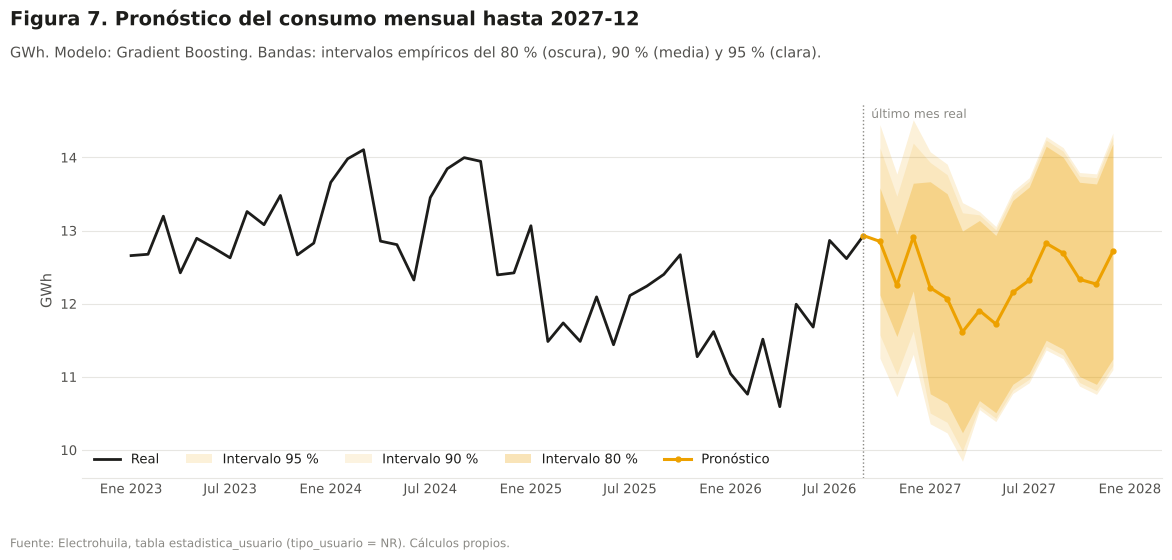

In [13]:
fig, ax = FIG.nueva(f'Pronóstico del consumo mensual hasta {P.MES_OBJETIVO}',
                    f'GWh. Modelo: {MEJOR}. Bandas: intervalos empíricos del 80 % (oscura), 90 % (media) y 95 % (clara).', alto=5.4)
h = serie.loc['2023-01':]
ax.plot(h.index, h / GWH, color=utils.TINTA, lw=2, label='Real')
f = pron['FECHA']
ax.fill_between(f, pron['Inferior_95'] / GWH, pron['Superior_95'] / GWH, color=COL[MEJOR], alpha=.15, lw=0, label='Intervalo 95 %')
ax.fill_between(f, pron['Inferior_90'] / GWH, pron['Superior_90'] / GWH, color=COL[MEJOR], alpha=.12, lw=0, label='Intervalo 90 %')
ax.fill_between(f, pron['Inferior_80'] / GWH, pron['Superior_80'] / GWH, color=COL[MEJOR], alpha=.28, lw=0, label='Intervalo 80 %')
ax.plot([h.index[-1], *f], [h.iloc[-1] / GWH, *(pron['Pronóstico_kWh'] / GWH)], color=COL[MEJOR], lw=2.2, marker='o', ms=3.5, label='Pronóstico')
ax.axvline(h.index[-1], color=utils.TINTA_3, lw=1, ls=':')
ax.text(h.index[-1], ax.get_ylim()[1] * .995, '  último mes real', fontsize=8.8, color=utils.TINTA_3, va='top')
ax.set_ylabel('GWh'); ax.legend(loc='lower left', ncol=5)
utils.eje_fechas_es(ax)
FIG.guardar(fig, 'pronostico_global')

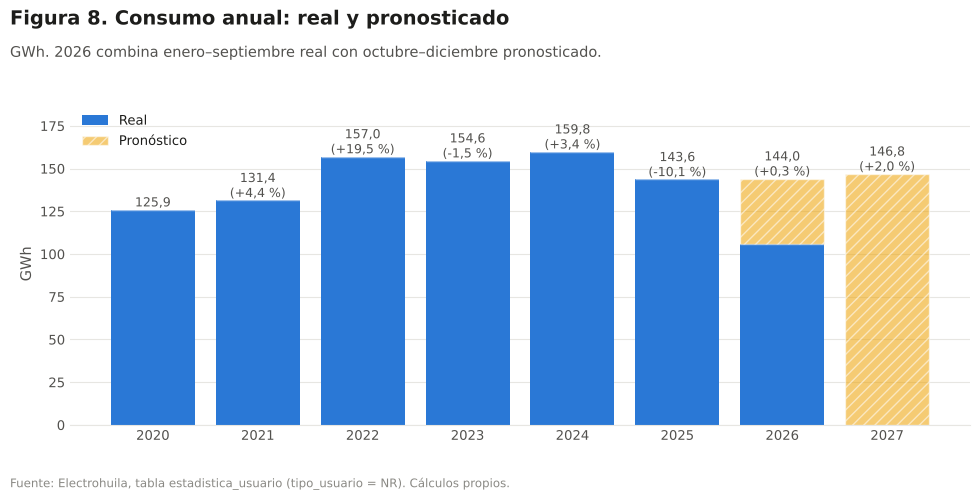

,Real (GWh),Pronóstico (GWh),Total (GWh),Variación %,Meses reales
Año,,,,,
2020,125.88,0.00,125.88,NaN,12
2021,131.37,0.00,131.37,4.37,12
2022,156.99,0.00,156.99,19.50,12
2023,154.56,0.00,154.56,-1.55,12
2024,159.79,0.00,159.79,3.39,12
2025,143.62,0.00,143.62,-10.12,12
2026,106.00,38.01,144.02,0.27,9
2027,0.00,146.84,146.84,1.96,0


In [14]:
res_parcial = P.Resultados(base, serie, cal, bt, hiper, comp, pron, modelo_final, {}, {})
anual = P.resumen_anual(res_parcial)
fig, ax = FIG.nueva('Consumo anual: real y pronosticado', 'GWh. 2026 combina enero–septiembre real con octubre–diciembre pronosticado.',
                    ancho=10, alto=4.8)
x = anual['Año'].astype(str)
ax.bar(x, anual['Real (GWh)'], color=utils.AZUL, label='Real')
ax.bar(x, anual['Pronóstico (GWh)'], bottom=anual['Real (GWh)'], color=COL[MEJOR], alpha=.55, hatch='///', edgecolor='white',
       label='Pronóstico')
for xi, tot, v in zip(x, anual['Total (GWh)'], anual['Variación %']):
    ax.text(xi, tot + 2, utils.fmt_es(tot, 1) + ('' if pd.isna(v) else f'\n({"+" if v > 0 else ""}{utils.fmt_es(v, 1)} %)'),
            ha='center', fontsize=9, color=utils.TINTA_2)
ax.set_ylim(0, anual['Total (GWh)'].max() * 1.18); ax.set_ylabel('GWh'); ax.legend(loc='upper left')
FIG.guardar(fig, 'consumo_anual_real_y_pronostico')
anual.round(2).set_index('Año')

**Interpretación — pronóstico global.**
- **Qué muestra:** el pronóstico mensual hasta diciembre de 2027 con sus intervalos, y los totales anuales.
- **Hallazgos:** el modelo proyecta un consumo estable, alrededor de 12 GWh/mes, con el patrón estacional observado: más alto en julio–octubre y diciembre, más bajo en febrero–mayo. El total de 2026 queda cerca de 144 GWh, similar a 2025, y el de 2027 en torno a 147 GWh (≈ +2 %). Es decir, no se espera la recuperación del nivel de 2022–2024 ni una nueva caída.

## 6. Pronóstico por usuario y por cuenta

Cada usuario y cada cuenta **activa**, es decir, con registro en septiembre de 2026, recibe su propio modelo:

1. **Serie de cada entidad:** empieza en su primer registro, y los meses sin registro intermedios cuentan como 0 kWh.
2. **Evaluación:** si la historia permite apartar 12 meses de prueba, se evalúan los modelos que caben en el resto y se elige el de **menor MAE** en esa prueba. Si no, se usa el promedio móvil de 12 meses.
3. **Pronóstico mensual:** el modelo elegido se reentrena con toda la serie y pronostica mes a mes hasta diciembre de 2027.
4. **Intervalos del 80 % y 90 %:** ± el percentil 80 y 90 del error absoluto (kWh) que tuvo el modelo elegido en la prueba de 12 meses de esa misma entidad. Después de 12 meses se amplían con √(h/12). Si la entidad no tuvo prueba, se usa el error relativo típico del nivel aplicado a su pronóstico.

A este nivel se usan hiperparámetros fijos, con menos árboles, para que el cálculo sobre más de 700 series tome pocos minutos. Las entidades sin registro en el último mes no se pronostican: se asume que dejaron de consumir.

En `predicciones.xlsx` (hojas *Por usuario* y *Por cuenta*) y en el dashboard aparecen **los 152 usuarios y las 701 cuentas**: una fila por entidad con su número real de cuenta, estado, modelo, métricas y pronóstico mes a mes. Las que no se pronostican quedan listadas con el motivo.

In [15]:
usuarios = P.nivel_entidades(base, 'usuario', cal)
cuentas = P.nivel_entidades(base, 'cuenta', cal)
resumen_niveles = pd.concat({'Usuario': usuarios['resumen'], 'Cuenta': cuentas['resumen']}, axis=1)
resumen_niveles.round(2)

  usuario: 114 activos de 151 · 34 s
  cuenta: 601 activos de 700 · 199 s


Usuario                                                 Cuenta                                             
                     Entidades MAPE_mediano MASE_mediano WAPE_% Veces_mejor Entidades MAPE_mediano MASE_mediano WAPE_% Veces_mejor
Modelo                                                                                                                            
Gradient Boosting          106        16.38         0.69  15.36          14       568        18.08         0.48  16.66          57
Random Forest              106        15.92         0.68  15.88          20       568        15.72         0.44  16.90         118
Holt-Winters               107        17.73         0.68  16.57          18       576        21.07         0.53  17.21          61
Naive estacional           109        17.65         0.73  17.91          16       581        20.61         0.56  17.67          45
Ridge con rezagos          106        16.91         0.71  18.21          16       568        21.18         0.57  18.11          85
Promedio móvil 12 m        110        16.01         0.72  18.35          15       589        15.68         0.43  18.32         184
Regresión estacional       107        22.19         0.80  23.64          15       576        38.16         0.87  20.48          51

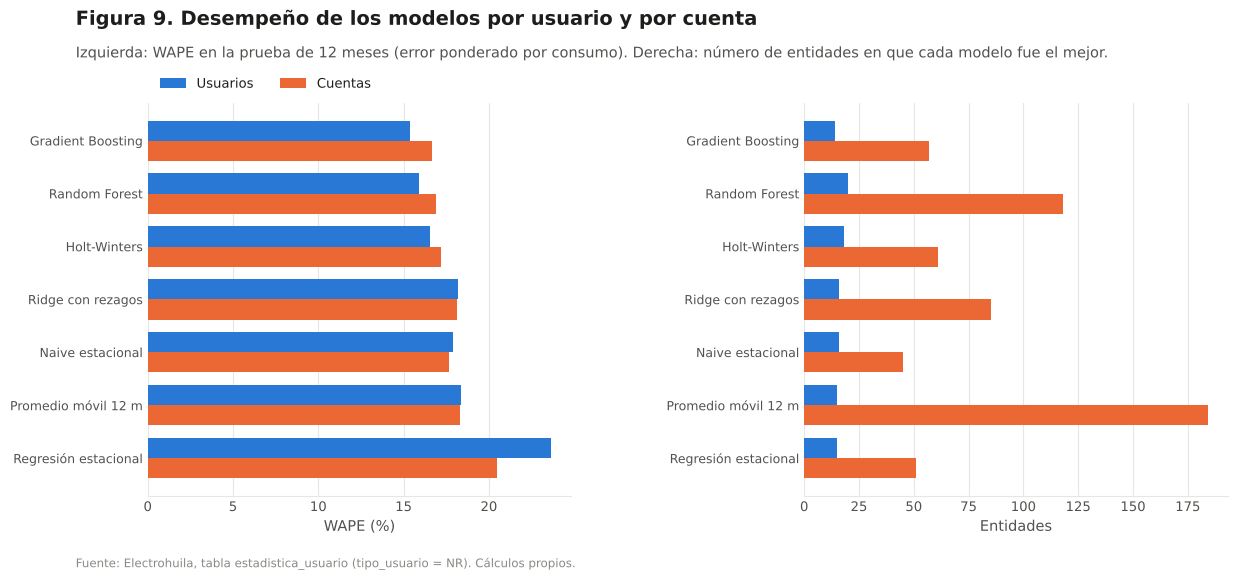

In [16]:
fig, (a1, a2) = FIG.nueva('Desempeño de los modelos por usuario y por cuenta',
                          'Izquierda: WAPE en la prueba de 12 meses (error ponderado por consumo). Derecha: número de entidades en que cada modelo fue el mejor.',
                          alto=5.6, columnas=2)
y = np.arange(len(ORDEN))
for k, (nivel, d, c) in enumerate([('Usuarios', usuarios, utils.AZUL), ('Cuentas', cuentas, utils.NARANJA)]):
    r_ = d['resumen'].reindex(ORDEN)
    a1.barh(y + (k - .5) * .38, r_['WAPE_%'], height=.38, color=c, label=nivel)
    a2.barh(y + (k - .5) * .38, r_['Veces_mejor'], height=.38, color=c, label=nivel)
for a in (a1, a2):
    a.set_yticks(y); a.set_yticklabels(ORDEN, fontsize=9); a.invert_yaxis(); a.grid(axis='x'); a.grid(axis='y', visible=False)
a1.set_xlabel('WAPE (%)'); a2.set_xlabel('Entidades')
a1.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2)
fig.subplots_adjust(wspace=0.55)
FIG.guardar(fig, 'modelos_por_usuario_y_cuenta')

Suma de usuarios vs global (todo el horizonte): -3.1 % · suma de cuentas vs global: -2.9 %
Usuarios activos pronosticados: 114 · cuentas activas pronosticadas: 601


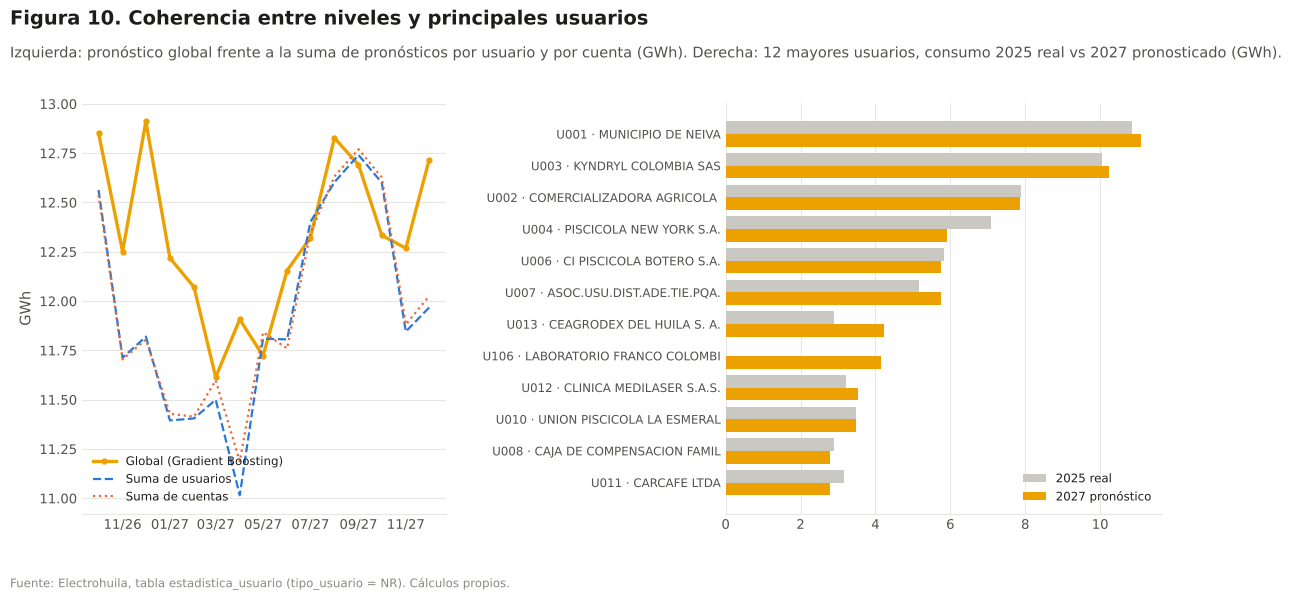

In [17]:
fechas_f = pron['FECHA']
suma_u = usuarios['pronostico'].sum().reindex(fechas_f)
suma_c = cuentas['pronostico'].sum().reindex(fechas_f)
cat_u = base.usuarios.set_index('CODIGO')
p27 = usuarios['pronostico'].loc[:, usuarios['pronostico'].columns.year == 2027].sum(axis=1)
r25 = usuarios['panel'].loc[:, usuarios['panel'].columns.year == 2025].sum(axis=1).reindex(p27.index)
top = p27.sort_values(ascending=False).head(12)
fig, (a1, a2) = FIG.nueva('Coherencia entre niveles y principales usuarios',
                          'Izquierda: pronóstico global frente a la suma de pronósticos por usuario y por cuenta (GWh). '
                          'Derecha: 12 mayores usuarios, consumo 2025 real vs 2027 pronosticado (GWh).',
                          alto=5.8, columnas=2, gridspec_kw={'width_ratios': [1, 1.2]})
a1.plot(fechas_f, pron['Pronóstico_kWh'] / GWH, color=COL[MEJOR], lw=2.4, marker='o', ms=3.5, label=f'Global ({MEJOR})')
a1.plot(fechas_f, suma_u / GWH, color=utils.AZUL, lw=1.6, ls='--', label='Suma de usuarios')
a1.plot(fechas_f, suma_c / GWH, color=utils.NARANJA, lw=1.6, ls=':', label='Suma de cuentas')
a1.set_ylabel('GWh'); a1.legend(loc='lower left', fontsize=8.5); a1.xaxis.set_major_formatter(mdates.DateFormatter('%m/%y'))
etq = [f'{c} · {cat_u.at[c, "ETIQUETA"][:26]}' for c in top.index]
yy = np.arange(len(top))
a2.barh(yy - .2, r25.loc[top.index] / GWH, height=.4, color='#c9c8c3', label='2025 real')
a2.barh(yy + .2, top / GWH, height=.4, color=COL[MEJOR], label='2027 pronóstico')
a2.set_yticks(yy); a2.set_yticklabels(etq, fontsize=8.5); a2.invert_yaxis(); a2.grid(axis='x'); a2.grid(axis='y', visible=False)
a2.legend(loc='lower right', fontsize=8.5)
fig.subplots_adjust(wspace=0.7)
FIG.guardar(fig, 'coherencia_y_principales_usuarios')
dif = (suma_u.sum() / pron['Pronóstico_kWh'].sum() - 1) * 100
print(f'Suma de usuarios vs global (todo el horizonte): {dif:+.1f} % · suma de cuentas vs global: '
      f'{(suma_c.sum() / pron["Pronóstico_kWh"].sum() - 1) * 100:+.1f} %')
print(f'Usuarios activos pronosticados: {len(usuarios["asignacion"])} · cuentas activas pronosticadas: {len(cuentas["asignacion"])}')

Ejemplo: pronóstico mensual de U001 (MUNICIPIO DE NEIVA) en MWh


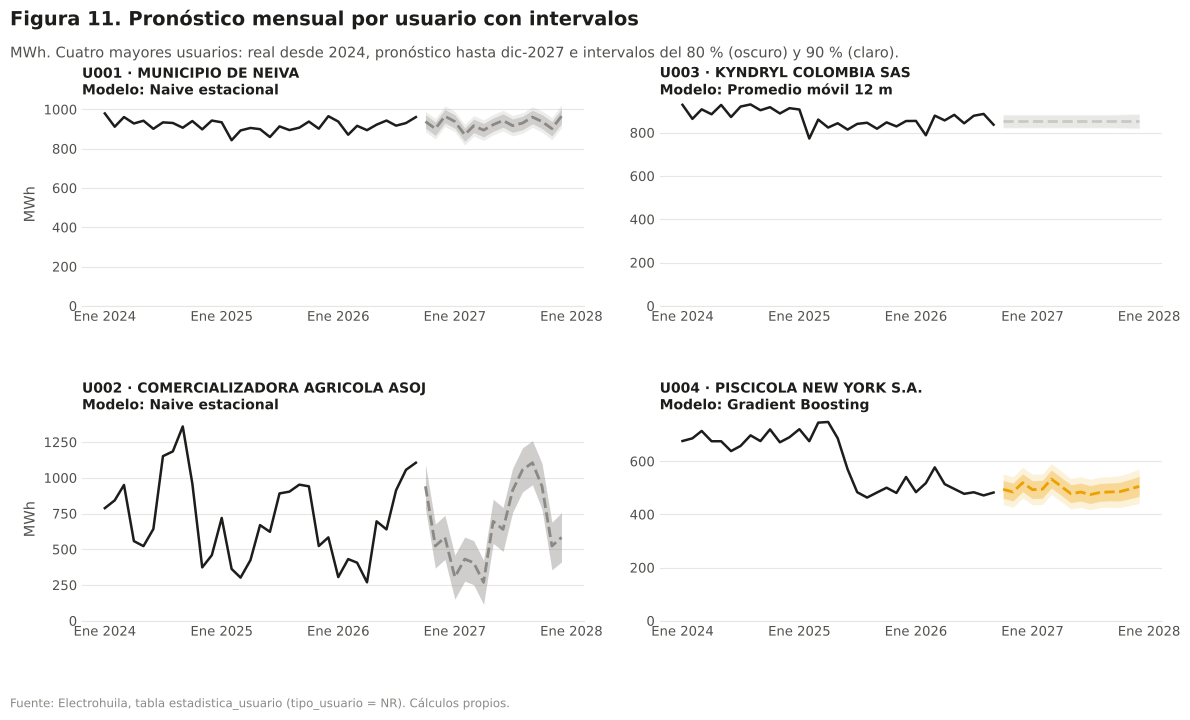

,Pronóstico (MWh),Inferior 80 % (MWh),Superior 80 % (MWh),Inferior 90 % (MWh),Superior 90 % (MWh)
Mes,,,,,
2026-10,937.90,903.80,972.10,885.70,990.10
2026-11,901.60,867.40,935.70,849.40,953.80
2026-12,965.20,931.10,999.40,913.00,"1,017.40"
2027-01,937.90,903.80,972.10,885.70,990.10
2027-02,870.90,836.70,905.00,818.70,923.10
2027-03,916.30,882.10,950.40,864.10,968.50
2027-04,894.10,860.00,928.30,841.90,946.30
2027-05,922.10,887.90,956.20,869.90,974.30
2027-06,943.00,908.90,977.20,890.80,995.20


In [18]:
# Pronóstico mensual con intervalos del 80 % y 90 % de los 4 mayores usuarios
int_u = P.intervalos_entidades(usuarios)
top4 = usuarios['pronostico'].sum(axis=1).sort_values(ascending=False).head(4).index
fig, axes = FIG.nueva('Pronóstico mensual por usuario con intervalos',
                      'MWh. Cuatro mayores usuarios: real desde 2024, pronóstico hasta dic-2027 e intervalos del 80 % (oscuro) y 90 % (claro).',
                      alto=7, filas=2, columnas=2)
for ax, cod in zip(axes.flat, top4):
    h = usuarios['panel'].loc[cod, '2024-01':] / 1e3
    d = int_u[int_u['Entidad'] == cod]
    m = usuarios['asignacion'].at[cod, 'Modelo']
    ax.plot(h.index, h.values, color=utils.TINTA, lw=1.8)
    ax.fill_between(d['Mes'], d['Inferior 90 % (kWh)'] / 1e3, d['Superior 90 % (kWh)'] / 1e3, color=COL[m], alpha=.15, lw=0)
    ax.fill_between(d['Mes'], d['Inferior 80 % (kWh)'] / 1e3, d['Superior 80 % (kWh)'] / 1e3, color=COL[m], alpha=.3, lw=0)
    ax.plot(d['Mes'], d['Pronóstico (kWh)'] / 1e3, color=COL[m], lw=2, ls='--')
    ax.set_title(f'{cod} · {cat_u.at[cod, "ETIQUETA"][:30]}\nModelo: {m}', fontsize=10)
    ax.set_ylim(bottom=0); utils.eje_fechas_es(ax, meses=(1,))
axes.flat[0].set_ylabel('MWh'); axes.flat[2].set_ylabel('MWh')
fig.subplots_adjust(hspace=0.55, wspace=0.15)
FIG.guardar(fig, 'intervalos_principales_usuarios')
t = int_u[int_u['Entidad'] == top4[0]].set_index('Mes').drop(columns=['Entidad'])
t.index = t.index.strftime('%Y-%m')
print(f'Ejemplo: pronóstico mensual de {top4[0]} ({cat_u.at[top4[0], "ETIQUETA"]}) en MWh')
(t.drop(columns='Meses adelante') / 1e3).round(1).rename(columns=lambda x: x.replace('(kWh)', '(MWh)'))

**Interpretación — usuarios y cuentas.**
- **Qué muestra:** el error de cada modelo cuando se aplica a cada usuario o cuenta, cuántas veces resultó el mejor, la coherencia con el pronóstico global y los usuarios de mayor consumo.
- **Hallazgos:**
  - **El error individual es mucho mayor que el global** (WAPE ≈ 15–18 % en los mejores modelos, frente a ≈ 7 %), porque los errores de las entidades se compensan al sumarlas.
  - **Gradient Boosting y Random Forest tienen el menor WAPE en ambos niveles**, pero ningún modelo domina: el mejor varía de una entidad a otra.
  - **En las cuentas pequeñas gana con frecuencia el promedio móvil de 12 meses.** Su consumo es irregular y un modelo simple pronostica mejor que uno complejo.
  - **La suma de los pronósticos individuales queda ≈ 3 % por debajo del global.** Los modelos por entidad no anticipan la aparición de cuentas nuevas, que sí está implícita en la serie total.

## 7. Exportación de resultados

- **`data/output/predicciones.xlsx`:**
  - pronóstico global con intervalos del 80 %, 90 % y 95 %;
  - resumen anual;
  - pronóstico por usuario y por cuenta: todos (152 y 701), una fila por entidad y una columna por mes;
  - pronóstico mensual por usuario y por cuenta con intervalos del 80 % y 90 % (hojas *Usuarios mensual* y *Cuentas mensual*);
  - real vs pronóstico de cada modelo en la prueba final;
  - coherencia entre niveles.
- **`data/output/indicadores.xlsx`:**
  - métricas de validación y de la prueba final;
  - error por horizonte;
  - hiperparámetros;
  - desempeño por nivel y modelo asignado a cada usuario y cuenta;
  - demanda anual.
- **`data/output/modelos/modelo_global.joblib`:** el modelo ganador entrenado, con sus métricas.
- **`static/js/data.js`:** los datos que usan los dos dashboards de `templates/`.

In [19]:
res = P.Resultados(base, serie, cal, bt, hiper, comp, pron, modelo_final, usuarios, cuentas)
rutas = P.exportar_resultados(res)
rutas['data_js'] = P.generar_data_js(res)
for k, v in rutas.items():
    print(f'{k:>13}: {Path(v).relative_to(RAIZ).as_posix()}')
print(f'\nFiguras: {len(list(FIG.carpeta.glob("*.png")))} en {FIG.carpeta.relative_to(RAIZ).as_posix()}/')
assert abs(serie.sum() - base.analisis['TOTAL_ACTIVA'].sum()) < 1, 'La serie no cuadra con la base'

 predicciones: data/output/predicciones.xlsx
  indicadores: data/output/indicadores.xlsx
       modelo: data/output/modelos/modelo_global.joblib
      data_js: static/js/data.js

Figuras: 11 en data/output/reportes/prediccion/figuras/


## 8. Conclusiones

1. **Modelo elegido.** Gradient Boosting con rezagos y calendario es el mejor para el consumo total. Tiene el menor MAPE en la validación con origen móvil (≈ 7,2 %) y en la prueba final (≈ 5,2 %), y reduce el MAE en ≈ 22 % frente al naive estacional (MASE ≈ 0,81). Holt-Winters es el respaldo más estable (2.º en la prueba final). Random Forest empata en la validación pero cae en la prueba final.
2. **Métricas.** MAE, RMSE, MAPE, WAPE y MASE coinciden en el ordenamiento. El R² es bajo o negativo porque el consumo mensual varía poco alrededor de su nivel y el cambio de nivel de 2025 no era predecible con la historia. En esta serie, el MAPE y el MAE son las métricas más informativas.
3. **Pronóstico.** Se espera un consumo estable, cerca de 12 GWh por mes. 2026 cerraría en torno a 144 GWh, similar a 2025, y 2027 en torno a 147 GWh, con la estacionalidad habitual (julio–octubre más altos).
4. **Niveles.** Por usuario y por cuenta el error es mayor (WAPE ≈ 15–18 %) y el mejor modelo varía. Para el total se usa el pronóstico global; los individuales sirven para el seguimiento de cada cliente.

### Limitaciones y próximos pasos
- **Variables externas:** agregar temperatura, actividad económica regional o tarifas a `variables_externas.csv` y medir si reducen el error.
- **Cambios de nivel:** las series de los usuarios con cambios estructurales, como la Fiduciaria Davivienda o el Municipio de Neiva, necesitan información del negocio para pronosticarse bien.
- **Actualización:** repetir la validación cada mes con los datos nuevos (*Run All*) y vigilar si cambia el modelo ganador.
- **Conciliación:** el pronóstico global y los individuales no suman lo mismo. Un siguiente paso es un pronóstico jerárquico que los haga coherentes.

## 9. Referencias

Bergmeir, C., & Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences, 191*, 192–213. https://doi.org/10.1016/j.ins.2011.12.028

Hong, T., & Fan, S. (2016). Probabilistic electric load forecasting: A tutorial review. *International Journal of Forecasting, 32*(3), 914–938. https://doi.org/10.1016/j.ijforecast.2015.11.011

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting, 22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0